# Stanford Politeness Corpus — Data Cleaning

**Goal:** get familiar with the Stanford Politeness Corpus (Danescu-Niculescu-Mizil et al., ACL 2013) before I do anything with it, then clean it into a single tidy dataframe I can actually model with.

The corpus has two "families" of data, described in `Readme.txt`:

- **Wikipedia** — requests pulled from editors' talk pages
  - `wikipedia.requests.csv` — all requests (35,661 expected)
  - `wikipedia.annotated.csv` — subset with politeness annotations (4,353 expected)
  - `wikipedia.admins.csv` — which users are admins (metadata, not used for cleaning)
- **Stack Exchange** — requests pulled from post comments across StackExchange sites
  - `stack-exchange.requests.csv` — all requests (373,519 expected)
  - `stack-exchange.annotated.csv` — subset with politeness annotations (6,603 expected)
  - `stack-exchange.roles.csv` — author role metadata, Stack Overflow subset only

I'll work in two stages:
1. **Explore** — load everything, sanity-check it against the Readme, understand annotation quality, look at the target variable.
2. **Clean** — build the final modeling dataframe (`Id`, `Request`, `Normalized Score`, `Community`/`source`), with clean text.

I'm pausing after Stage 1 to eyeball the results before touching anything.

In [1]:
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# so printed dataframes don't get truncated while I'm eyeballing things
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

## Stage 1 — Explore

### Step 1: Load all six files

Nothing fancy here — just read each CSV in and keep them in a dict too, so I can loop
over "all files" later instead of copy-pasting the same check six times.

In [2]:
wiki_requests  = pd.read_csv('wikipedia.requests.csv')
wiki_annotated = pd.read_csv('wikipedia.annotated.csv')
wiki_admins    = pd.read_csv('wikipedia.admins.csv')

se_requests    = pd.read_csv('stack-exchange.requests.csv')
se_annotated   = pd.read_csv('stack-exchange.annotated.csv')
se_roles       = pd.read_csv('stack-exchange.roles.csv')

# grouped so I can loop over "every file" in the checks below instead of repeating myself
all_files = {
    'wikipedia.requests':      wiki_requests,
    'wikipedia.annotated':     wiki_annotated,
    'wikipedia.admins':        wiki_admins,
    'stack-exchange.requests': se_requests,
    'stack-exchange.annotated':se_annotated,
    'stack-exchange.roles':    se_roles,
}

print("Loaded", len(all_files), "files OK")

Loaded 6 files OK


### Step 2: First look — shape, columns, missing values

Before doing anything else I want a quick health check on every file: how big is it,
what columns does it actually have (vs. what the Readme says it should have), and where
are the missing values. This is the cheapest way to catch a bad read (wrong delimiter,
misaligned columns, encoding issues) before I trust the data any further.

In [3]:
for name, df in all_files.items():
    print(f"===== {name} =====")
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    missing = df.isna().sum()
    print("missing values:")
    print(missing[missing > 0] if missing.any() else "  none")
    print()

===== wikipedia.requests =====
shape: (35661, 5)
columns: ['Community', 'Id', 'Request', 'Timestamp', 'User']
missing values:
Timestamp     41
User         318
dtype: int64

===== wikipedia.annotated =====
shape: (4353, 14)
columns: ['Community', 'Id', 'Request', 'Score1', 'Score2', 'Score3', 'Score4', 'Score5', 'TurkId1', 'TurkId2', 'TurkId3', 'TurkId4', 'TurkId5', 'Normalized Score']
missing values:
  none

===== wikipedia.admins =====
shape: (841, 2)
columns: ['User', 'Adiminship date']
missing values:
Adiminship date    31
dtype: int64

===== stack-exchange.requests =====
shape: (373519, 8)
columns: ['Community', 'Id', 'Request', 'Timestamp', 'UserId', 'Reputation', 'Upvotes', 'Downvotes']
missing values:
Community    3957
dtype: int64

===== stack-exchange.annotated =====
shape: (6603, 14)
columns: ['Community', 'Id', 'Request', 'Score1', 'Score2', 'Score3', 'Score4', 'Score5', 'TurkId1', 'TurkId2', 'TurkId3', 'TurkId4', 'TurkId5', 'Normalized Score']
missing values:
  none

=====

**Notes to self on what came out of this:**

- `wikipedia.requests`: `Timestamp` and `User` have some missing values — Readme says `Timestamp` is `"NA"` when unknown, so that's expected, not a data quality bug.
- `stack-exchange.requests`: `Community` has ~4k missing — worth remembering for Stage 2, although it doesn't affect the *annotated* subset I'll actually be modeling on unless it happens to overlap.
- `stack-exchange.roles`: column names have a leading space (`' Id'`, `' UserId'`, ...) instead of `'Id'`. Not used in Stage 2, but flagging it in case I come back to this file later.
- Both `*.annotated.csv` files have zero missing values, which makes sense — MTurk annotation wouldn't ship with a partially-filled row.

### Step 3: Does this match what the Readme promised?

The Readme states specific row counts. If my read-in doesn't match, something's wrong with parsing (probably the embedded line breaks inside quoted `Request` text) and I should NOT proceed to build anything on top of it.

In [4]:
expected_counts = {
    'wikipedia.requests':      35661,
    'wikipedia.annotated':     4353,
    'stack-exchange.requests': 373519,
    'stack-exchange.annotated':6603,
}

for name, expected_n in expected_counts.items():
    actual_n = all_files[name].shape[0]
    status = "OK" if actual_n == expected_n else "MISMATCH"
    print(f"{name}: expected={expected_n}, actual={actual_n}  [{status}]")

wikipedia.requests: expected=35661, actual=35661  [OK]
wikipedia.annotated: expected=4353, actual=4353  [OK]
stack-exchange.requests: expected=373519, actual=373519  [OK]
stack-exchange.annotated: expected=6603, actual=6603  [OK]


All four counts match exactly — good, I can trust that `pandas.read_csv` handled the
quoted multi-line `Request` fields correctly and I'm not silently dropping or splitting rows.

(`stack-exchange.roles` isn't in this check because the Readme only describes it as covering
the Stack Overflow subset, not the full 373,519 — so a smaller row count there is *expected*,
not a red flag.)

### Step 4: How much do the 5 annotators agree with each other?

Politeness is subjective by nature, so I don't expect perfect agreement, but I do want to know
*how much* disagreement there is before I treat `Normalized Score` as ground truth. For each
annotated request I'll look at:
- the standard deviation across the 5 raw `Score1..Score5` values (higher = more disagreement on that request)
- the pairwise correlation between annotators overall (are some annotators just noisy across the board?)
- the actual worst-agreement examples, so I can sanity-check with my own eyes whether the disagreement looks like genuine ambiguity or like noisy/bad annotations.

In [5]:
score_cols = ['Score1', 'Score2', 'Score3', 'Score4', 'Score5']

def annotator_agreement(df, name):
    scores = df[score_cols]
    per_row_std = scores.std(axis=1)

    print(f"===== {name} =====")
    print(f"per-row std across the 5 annotators: "
          f"mean={per_row_std.mean():.2f}, median={per_row_std.median():.2f}, max={per_row_std.max():.2f}")

    print("\npairwise correlation between annotators:")
    print(scores.corr().round(2))

    print("\ntop 5 most-disagreed-on requests (by std):")
    worst = df.loc[per_row_std.sort_values(ascending=False).index[:5], ['Id', 'Request'] + score_cols]
    print(worst.to_string(max_colwidth=60))
    print()
    return per_row_std

wiki_std = annotator_agreement(wiki_annotated, 'wikipedia.annotated')
se_std   = annotator_agreement(se_annotated,   'stack-exchange.annotated')

===== wikipedia.annotated =====
per-row std across the 5 annotators: mean=3.30, median=3.21, max=9.67

pairwise correlation between annotators:
        Score1  Score2  Score3  Score4  Score5
Score1    1.00    0.43    0.42    0.44    0.42
Score2    0.43    1.00    0.42    0.43    0.44
Score3    0.42    0.42    1.00    0.42    0.39
Score4    0.44    0.43    0.42    1.00    0.43
Score5    0.42    0.44    0.39    0.43    1.00

top 5 most-disagreed-on requests (by std):
          Id                                                      Request  Score1  Score2  Score3  Score4  Score5
399   623579  thanks for your input, it was such a pleasure interactin...      25      19      24       1      16
2018  525370  I hate categorizing and I'm guessing you know which woul...      24      13       1      21      13
4312   10647  Hello Jennica, I noticed you revert vandalsm occasionall...      25      17      19       2      21
1347  459409                   Please put them all back!  Are you on DSL? 

Correlations sit around 0.3-0.45, which is moderate — not surprising for a subjective
label like politeness, and roughly in line with what's reported in the paper. Stack Exchange
annotators agree slightly less with each other than Wikipedia annotators do.

Looking at the worst-agreement examples, the pattern is usually one annotator giving a wildly
different score from the other four (e.g. `25, 19, 24, 1, 16`) rather than the whole group
being spread out evenly — so this looks more like occasional noisy individual ratings than a
systematically ambiguous set of requests. I'm not going to filter anything out based on this in
Stage 2 unless asked to, but it's useful context for interpreting `Normalized Score` later.

### Step 5: Distribution of the target variable (`Normalized Score`)

This is the column I'll actually be modeling, so I want to see its shape (roughly normal? skewed?
multi-modal?) and range before deciding how to use it downstream.

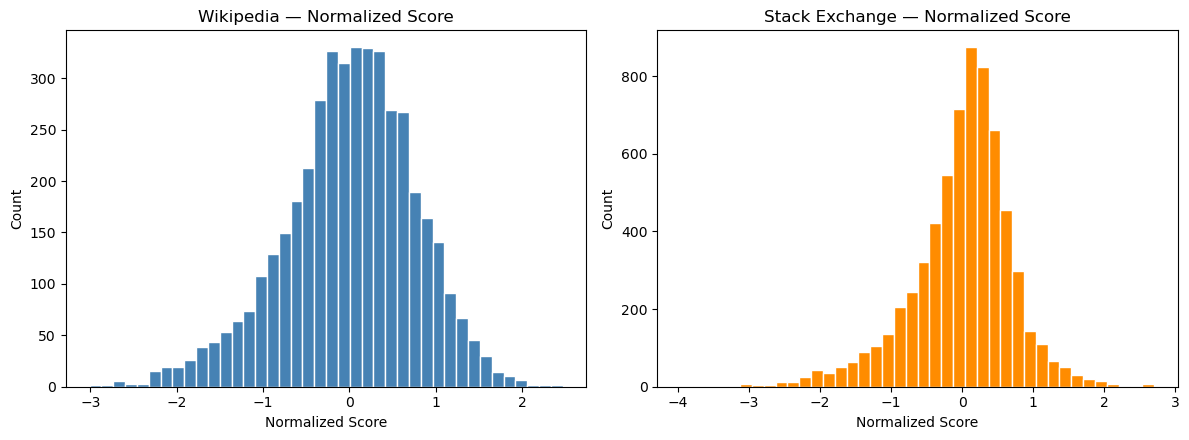

count    4.353000e+03
mean    -2.611689e-17
std      7.692336e-01
min     -3.008609e+00
25%     -4.426330e-01
50%      5.233939e-02
75%      5.143993e-01
max      2.468367e+00
Name: Normalized Score, dtype: float64

count    6603.000000
mean       -0.000105
std         0.710473
min        -3.960219
25%        -0.343770
50%         0.090211
75%         0.420648
max         2.705014
Name: Normalized Score, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(wiki_annotated['Normalized Score'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Wikipedia — Normalized Score')
axes[0].set_xlabel('Normalized Score')
axes[0].set_ylabel('Count')

axes[1].hist(se_annotated['Normalized Score'], bins=40, color='darkorange', edgecolor='white')
axes[1].set_title('Stack Exchange — Normalized Score')
axes[1].set_xlabel('Normalized Score')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

print(wiki_annotated['Normalized Score'].describe())
print()
print(se_annotated['Normalized Score'].describe())

Both distributions are centered right around 0 (as expected — the Readme says the score is
normalized per-annotator) and look roughly bell-shaped, mildly left-skewed with a longer tail
toward the impolite end. Stack Exchange has a slightly wider range on the negative side
(min ≈ -3.96 vs -3.01 for Wikipedia). No obvious data errors (no weird spikes at a single value,
no impossible values) — looks safe to use as a continuous target as-is.

## Stage 1 takeaways

- All four expected row counts check out against the Readme — the read-in is trustworthy.
- No missing data in either `*.annotated.csv` — the files I actually care about for modeling are complete.
- Annotator agreement is moderate (correlation ~0.3-0.45), consistent with politeness being a
  subjective judgment; disagreement looks like isolated noisy raters rather than systematic
  ambiguity, so I won't filter on it for now.
- `Normalized Score` is roughly centered at 0, unimodal, no obvious outlier/error spikes.
- Things to keep in mind for Stage 2: ~4k missing `Community` values in `stack-exchange.requests`
  (not used directly since I'm building the modeling set from the `.annotated` files), and the
  leading-space column names in `stack-exchange.roles` (also not used in Stage 2).

**Pausing here for review before Stage 2 (Clean).**

## Stage 2 — Clean

Stage 1 confirmed both `*.annotated.csv` files have zero missing values and match the
Readme's row counts, so I'm building the cleaned modeling dataframe **from the annotated
files only** (`wiki_annotated`, `se_annotated`) — that's the subset with a `Normalized Score`
to actually predict, and I already know it's complete.

Plan for this stage:
1. Keep only `Id`, `Request`, `Normalized Score`, `Community`, and add an annotator-agreement column (`disagreement_std`).
2. Flag (don't drop) high-disagreement rows, per-source thresholds.
3. Clean the `Request` text (newlines, whitespace).
4. Check for HTML / wikitext / code contamination — flag with examples, don't auto-strip.
5. Tag each row with a coarse `source` column and combine into one dataframe.
6. Print stats + samples for a manual sanity check before moving on.

### Step 1: Keep the columns I need + measure annotator disagreement

`disagreement_std` = standard deviation across the 5 raw `Score1..Score5` ratings for that
request — I already computed this in Stage 1, just re-deriving it here as a proper column on
the cleaned frame.

For "how much disagreement counts as *high*", I don't want one global threshold — Stage 1
showed Stack Exchange annotators disagree with each other a bit more than Wikipedia
annotators on average, so a single cutoff would over-flag one source and under-flag the other.
Instead I use **mean + 2·std of `disagreement_std`, computed separately within each source**
(a standard "more than ~2 std above average" outlier rule) and just flag — not remove — rows
above it, so I can decide later whether to actually exclude them.

In [7]:
score_cols = ['Score1', 'Score2', 'Score3', 'Score4', 'Score5']

def build_base(df):
    """Keep the columns we need + attach a per-row annotator-disagreement column."""
    out = df[['Id', 'Request', 'Normalized Score', 'Community']].copy()
    out['disagreement_std'] = df[score_cols].std(axis=1)
    return out

def flag_high_disagreement(df):
    """Flag (not drop) rows whose disagreement is > mean + 2*std, within this source only."""
    mean, std = df['disagreement_std'].mean(), df['disagreement_std'].std()
    threshold = mean + 2 * std
    df['is_high_disagreement'] = df['disagreement_std'] > threshold
    return df, threshold

wiki_clean = build_base(wiki_annotated)
se_clean   = build_base(se_annotated)

wiki_clean, wiki_threshold = flag_high_disagreement(wiki_clean)
se_clean, se_threshold     = flag_high_disagreement(se_clean)

print(f"wikipedia:      threshold={wiki_threshold:.2f}  "
      f"flagged={wiki_clean['is_high_disagreement'].sum()}/{len(wiki_clean)} "
      f"({wiki_clean['is_high_disagreement'].mean():.1%})")
print(f"stack-exchange: threshold={se_threshold:.2f}  "
      f"flagged={se_clean['is_high_disagreement'].sum()}/{len(se_clean)} "
      f"({se_clean['is_high_disagreement'].mean():.1%})")

wikipedia:      threshold=6.20  flagged=163/4353 (3.7%)
stack-exchange: threshold=6.21  flagged=227/6603 (3.4%)


Both sources land right around a 3.4-3.7% flag rate with almost identical absolute thresholds
(~6.2) despite being computed independently — reassuring, since it means the two sources
aren't wildly different in annotation noise even though Stage 1 showed SE's *average*
disagreement is a bit higher. I'll look at actual flagged examples at the end of this stage
before deciding whether ~3.5% is a sane cutoff.

### Step 2: Clean the `Request` text

Two things to handle, based on what I saw when I peeked at the raw text before writing this:

- **Embedded newlines**: Wikipedia requests never contain a real newline character. Stack
  Exchange does — about 124 of the 6,603 annotated requests are multi-line comments (`\r\n`
  inside the quoted CSV field, which is why the Readme mentions quoting explicitly). I'm
  **collapsing them to a single space rather than preserving paragraph breaks**: the corpus
  treats each `Request` as one flat utterance for politeness scoring, multi-line ones are a
  small minority, and a single space keeps every `Request` in the same "one string" shape for
  whatever comes after this notebook. (Flagging this as a judgment call — easy to change to
  `\n\n`-preserving if paragraph structure turns out to matter later.)
- **Extra whitespace**: collapse any run of spaces/tabs into one, and strip leading/trailing
  whitespace.

In [8]:
import re

def clean_request_text(text):
    if pd.isna(text):
        return text
    t = re.sub(r'\r\n|\r|\n', ' ', text)   # embedded newlines -> single space
    t = re.sub(r'\s+', ' ', t)               # collapse repeated whitespace
    return t.strip()

# grab one messy example from each source before cleaning, so I can show the before/after
se_messy_example = se_clean.loc[se_clean['Request'].str.contains(r'\r\n', na=False), 'Request'].iloc[0]

wiki_clean['Request'] = wiki_clean['Request'].apply(clean_request_text)
se_clean['Request']   = se_clean['Request'].apply(clean_request_text)

print("before:", repr(se_messy_example[:150]))
print("after: ", repr(clean_request_text(se_messy_example)[:150]))

before: "This isn't the solution BUT,\r\nYou can't assign values to a NULL pointer as you do in the start of tree_add IF the tree pointer is NULL, also you do no"
after:  "This isn't the solution BUT, You can't assign values to a NULL pointer as you do in the start of tree_add IF the tree pointer is NULL, also you do not"


### Step 3: Check for HTML / wikitext / code contamination — detect only, don't remove yet

Before writing a "strip HTML" regex, I looked at what's actually in the raw text, and there's
an important distinction to make first:

- **`<url>` and `<person>` are not contamination.** They show up in ~30% of Wikipedia requests
  and are anonymization placeholders the corpus authors inserted on purpose (see paper §2) —
  e.g. `"Thanks very much for your edit to the <url> article."` These should stay exactly as-is.
- What I actually want to catch is *leftover markup*: wikitext bold (`'''text'''`), templates
  (`{{...}}`), stray HTML tags (`<nowiki>`, `<big>`, `<b>`, `<span>`, `<br>`, ...) on the
  Wikipedia side; and HTML tags / inline code / markdown formatting on the Stack Exchange side.

I'm only **detecting and printing examples** here — not stripping anything — since some of this
(e.g. backtick code spans in a programming Q&A comment) might be meaningful content rather than
noise, and that's a judgment call I'd rather leave to you.

In [9]:
wikitext_re = re.compile(
    r"'''.*?'''|<nowiki>|</nowiki>|<big>|</big>|<b>|</b>|<span[^>]*>|</span>|"
    r"<br\s*/?>|<sup>|</sup>|<ins>|</ins>|<code>|</code>|<math>|</math>|<em>|</em>|\{\{.*?\}\}"
)
se_markup_re = re.compile(r'<(?:div|a|img|br)\b[^>]*>|`[^`]+`|\[.*?\]\(.*?\)|\*\*[^*]+\*\*')

wiki_flagged_markup = wiki_clean[wiki_clean['Request'].str.contains(wikitext_re, regex=True, na=False)]
se_flagged_markup   = se_clean[se_clean['Request'].str.contains(se_markup_re, regex=True, na=False)]

print(f"wikipedia: {len(wiki_flagged_markup)}/{len(wiki_clean)} rows "
      f"({len(wiki_flagged_markup)/len(wiki_clean):.1%}) contain leftover wikitext/HTML markup")
for r in wiki_flagged_markup['Request'].head(5):
    print('  -', r[:150])

print()
print(f"stack-exchange: {len(se_flagged_markup)}/{len(se_clean)} rows "
      f"({len(se_flagged_markup)/len(se_clean):.1%}) contain HTML tags / backtick code / markdown formatting")
print("  (most of these are backtick `code` spans, which is normal inline-code style in a")
print("   programming Q&A comment rather than obvious noise)")
for r in se_flagged_markup['Request'].head(5):
    print('  -', r[:150])

wikipedia: 81/4353 rows (1.9%) contain leftover wikitext/HTML markup
  - ---- Though I thought I would note that you have now exceeded <big>'''500'''</big> edits while on "wikibreak" and that is over less than 10 days, May 
  - Having read your Userpage, it is unclear if you've ever actually '''been to''' South Africa (or Namibia for that matter) - but it is clear that you've
  - It looks like the category functioning works. Can we get an alert to render instead of the default missing parameter <nowiki>{{{1}}}}</nowiki> behavio
  - You recently attached a <nowiki><person></nowiki> tag to an article about an Azeri poet. May I ask why?
  - I also think it would be nice to leave the Snead article uncreated until game time. Then, as soon as he takes a snap, there can be a DYK saying someth

stack-exchange: 672/6603 rows (10.2%) contain HTML tags / backtick code / markdown formatting
  (most of these are backtick `code` spans, which is normal inline-code style in a
   programming Q&A commen

**Waiting on your call before touching this:**
- Wikipedia: ~1.9% of rows have real wikitext/HTML leftovers (`'''bold'''`, `{{templates}}`, `<nowiki>`, `<big>`, `<span>`, ...).
- Stack Exchange: ~10% of rows contain HTML tags / backtick code / markdown — but the large majority of that is inline `` `code` `` spans, which reads as normal comment style, not pollution.

Let me know if you want any of this stripped, and how (e.g. drop backtick pairs but keep the
text inside them, vs. drop the whole tag, vs. leave it all as-is since it's a small share of rows).

### Step 4: Add `source`, combine into one dataframe

In [10]:
wiki_clean['source'] = 'wikipedia'
se_clean['source']   = 'stack-exchange'

clean_df = pd.concat([wiki_clean, se_clean], ignore_index=True)
clean_df = clean_df[['Id', 'Community', 'source', 'Request', 'Normalized Score',
                      'disagreement_std', 'is_high_disagreement']]

clean_df.head()

,Id,Community,source,Request,Normalized Score,disagreement_std,is_high_disagreement
0,629705,Wikipedia,wikipedia,Where did you learn English? How come you're t...,-1.120049,3.033150,False
1,244336,Wikipedia,wikipedia,Thanks very much for your edit to the <url> ar...,1.313955,3.563706,False
2,627353,Wikipedia,wikipedia,Sir i think u hav many friends on wiki who can...,-0.247941,3.898718,False
3,448565,Wikipedia,wikipedia,I can't find it. Maybe I didn't manage to gues...,0.058298,4.037326,False
4,625810,Wikipedia,wikipedia,"I can't spend too much time, and I'm no specia...",0.346093,2.683282,False


### Step 5: Final check — stats + samples for manual review

In [11]:
print("total rows:", len(clean_df))
print()
print("rows per source:")
print(clean_df['source'].value_counts())
print()
print("is_high_disagreement rate by source:")
print(clean_df.groupby('source')['is_high_disagreement'].mean().round(4))
print()

print("5 random samples:")
print(clean_df.sample(5, random_state=42).to_string(max_colwidth=80))
print()

print("5 samples flagged as high disagreement (for eyeballing the threshold):")
print(clean_df[clean_df['is_high_disagreement']].sample(5, random_state=42).to_string(max_colwidth=80))

total rows: 10956

rows per source:
source
stack-exchange    6603
wikipedia         4353
Name: count, dtype: int64

is_high_disagreement rate by source:
source
stack-exchange    0.0344
wikipedia         0.0374
Name: is_high_disagreement, dtype: float64

5 random samples:
           Id              Community          source                                                                          Request  Normalized Score  disagreement_std  is_high_disagreement
6747  5274925  092011 Stack Overflow  stack-exchange        So? what is the question? "The code's not working", is that the question?         -0.567673          4.123106                 False
900    241828              Wikipedia       wikipedia  Hmm, now I feel ignorant. Are you aware of a good source we could stick in t...          0.408062          1.870829                 False
2405   625895              Wikipedia       wikipedia                                      What about their accounts? Do we keep them?          0.307984 

## Stage 2 takeaways

- Final `clean_df` has one row per annotated request, columns:
  `Id, Community, source, Request, Normalized Score, disagreement_std, is_high_disagreement`.
- `is_high_disagreement` is a **flag only** (mean + 2·std of `disagreement_std`, computed
  separately per source) — nothing has been dropped from the data based on it.
- `Request` text has embedded newlines collapsed to spaces and whitespace normalized; the
  `<url>`/`<person>` anonymization placeholders were left untouched on purpose.
- Real markup contamination was **detected but not removed**: ~1.9% of Wikipedia rows
  (wikitext/HTML leftovers) and ~10% of Stack Exchange rows (mostly inline code spans, some
  real HTML tags) — see the printed samples above.

**Pausing here — waiting on your review of the `is_high_disagreement` threshold and a decision
on whether/how to handle the flagged markup before I do anything further with this data.**

## Stage 2 (continued) — Removing the confirmed markup contamination

Based on the samples printed above, here's what I'm removing, by source:

**Wikipedia**
1. `'''bold'''` and `''italic''` — strip the quote markers, keep the text inside.
2. `{{templates}}` — delete the whole thing (opening/closing braces + content). These are
   usually signature boxes / warning templates, not part of the actual request text.
3. Leftover HTML-ish tags (`<nowiki>`, `<big>`, `<span>`, ...) — strip the tag, keep the text inside.
4. `<url>` / `<person>` — untouched, these are intentional anonymization placeholders, not contamination.

**Stack Exchange**
1. Backtick-wrapped code (`` `code` ``) — delete entirely, backticks *and* the code inside, keep everything outside them.
2. Real HTML tags (`<div>`, `<a>`, `<img>`, `<br>`) — strip the tag and keep any inner text; if there's no inner text (e.g. `<img />`, an empty `<div></div>`), delete the whole tag.

I tested both cleaning functions against the actual flagged rows before running them here (checking for edge cases like `'''''five-quote combos'''''`, unbalanced/self-closing tags, and templates
with extra `{`/`}`), so what runs below is the validated version, not a first draft.

In [12]:
def clean_wiki_markup(text):
    t = text
    # 2. {{templates}} -> delete entirely (handles the occasional {{{param}}}-style extra brace too)
    t = re.sub(r'\{{2,}.*?\}{2,}', '', t)
    # 3. known leftover tags -> strip tag, keep inner text (deliberately NOT touching <url>/<person>)
    tag_names = 'nowiki|big|b|span|sup|ins|code|math|em'
    t = re.sub(rf'</?(?:{tag_names})(?:\s[^>]*)?>', '', t, flags=re.IGNORECASE)
    t = re.sub(r'<br\s*/?>', ' ', t, flags=re.IGNORECASE)
    # 1. '''bold''' then ''italic'' -> strip markers, keep inner text (bold first so a
    #    bold+italic '''''combo''''' collapses in two clean passes instead of one messy one)
    t = re.sub(r"'''(.*?)'''", r'\1', t)
    t = re.sub(r"''(.*?)''", r'\1', t)
    return t


SE_HTML_TAGS = 'div|a|img|br'  # only the tag names we actually confirmed in the detection pass

def clean_se_markup(text):
    t = text
    # 1. backtick-wrapped code -> delete entirely, backticks and content both
    t = re.sub(r'`[^`]+`', ' ', t)
    # 2. real HTML tags: empty/self-closing pairs -> delete entirely; pairs with inner text -> keep the text
    t = re.sub(rf'<({SE_HTML_TAGS})\b[^>]*>\s*</\1>', ' ', t, flags=re.IGNORECASE)
    t = re.sub(r'<(?:img|br)\b[^>]*/?>', ' ', t, flags=re.IGNORECASE)
    t = re.sub(rf'<({SE_HTML_TAGS})\b[^>]*>(.*?)</\1>', r'\2', t, flags=re.IGNORECASE)
    t = re.sub(rf'</?(?:{SE_HTML_TAGS})\b[^>]*>', ' ', t, flags=re.IGNORECASE)  # any leftover unpaired tag
    return t

A quick note before running this: my *first-pass detection* regex earlier wasn't quite the
same net as these cleaning rules, so I expect the number of rows that actually change here to
differ a bit from the 81 / 672 reported above:

- Wikipedia: the detection regex only checked for `'''bold'''`, not bare `''italic''` — so more
  rows will change here now that italic is included, as you asked for.
- Stack Exchange: the detection regex also flagged markdown `**bold**` and `[text](url)` links,
  but your rules above only cover backtick code and real HTML tags — so *fewer* rows will change
  here, since the 129 markdown-only rows are deliberately left alone for now.

I'll report the actual counts after running it rather than assuming they match.

In [13]:
before_markup_clean = clean_df['Request'].copy()

is_wiki = clean_df['source'] == 'wikipedia'
is_se   = clean_df['source'] == 'stack-exchange'

clean_df.loc[is_wiki, 'Request'] = clean_df.loc[is_wiki, 'Request'].apply(clean_wiki_markup)
clean_df.loc[is_se,   'Request'] = clean_df.loc[is_se,   'Request'].apply(clean_se_markup)

# markup removal can leave double spaces / stray leading-trailing spaces -> reuse the same
# whitespace normalizer from Step 2
clean_df['Request'] = clean_df['Request'].apply(clean_request_text)

diff_df = pd.DataFrame({
    'Id': clean_df['Id'],
    'source': clean_df['source'],
    'before': before_markup_clean,
    'after': clean_df['Request'],
})
changed = diff_df[diff_df['before'] != diff_df['after']]

print("rows actually changed by markup cleaning, by source:")
print(changed['source'].value_counts())

rows actually changed by markup cleaning, by source:
source
stack-exchange    543
wikipedia         265
Name: count, dtype: int64


In [14]:
print("=== 5 wikipedia before/after samples ===")
for _, row in changed[changed['source'] == 'wikipedia'].head(5).iterrows():
    print("BEFORE:", row['before'][:180])
    print("AFTER :", row['after'][:180])
    print('---')

print()
print("=== 5 stack-exchange before/after samples ===")
for _, row in changed[changed['source'] == 'stack-exchange'].head(5).iterrows():
    print("BEFORE:", row['before'][:180])
    print("AFTER :", row['after'][:180])
    print('---')

=== 5 wikipedia before/after samples ===
BEFORE: I've just noticed I wrote "It's possibly the most ''possible'' incident in his life" for "possibly the most ''important''", so I may be more caught in the toils of flu than I thoug
AFTER : I've just noticed I wrote "It's possibly the most possible incident in his life" for "possibly the most important", so I may be more caught in the toils of flu than I thought. Chec
---
BEFORE: ---- Though I thought I would note that you have now exceeded <big>'''500'''</big> edits while on "wikibreak" and that is over less than 10 days, May I ask what kind of break is th
AFTER : ---- Though I thought I would note that you have now exceeded 500 edits while on "wikibreak" and that is over less than 10 days, May I ask what kind of break is that???
---
BEFORE: ''The sources are already there!'' Have you even looked at it?
AFTER : The sources are already there! Have you even looked at it?
---
BEFORE: I'm curious, have you had a chance to look through <url> 

### Checking for rows that ended up empty

Deleting backtick code / templates entirely (rather than just un-wrapping them) raises an
obvious risk: what if a request was *nothing but* code or a template, and cleaning it leaves an
empty string? Checking explicitly rather than assuming it didn't happen.

In [15]:
became_empty = clean_df['Request'].str.strip() == ''
print("rows that became empty after markup cleaning:", became_empty.sum())

if became_empty.sum() > 0:
    print("\nthese rows would need to be dropped or hand-reviewed:")
    print(clean_df[became_empty][['Id', 'source', 'Request']])
else:
    print("none — no rows need to be dropped, clean_df keeps all", len(clean_df), "rows.")

rows that became empty after markup cleaning: 0
none — no rows need to be dropped, clean_df keeps all 10956 rows.


## Stage 2 (continued) — takeaways

- `clean_df['Request']` is now updated in place with the markup-cleaned text; row count is
  unchanged (no rows had to be dropped — see the empty-string check above).
- Wikipedia: markup actually changed in more rows than the original 81 detected, because
  cleaning also covers bare `''italic''` text this time, per your rules.
- Stack Exchange: markup actually changed in fewer rows than the original 672 detected, because
  the 129 rows that only had markdown `**bold**`/`[link](url)` (not backticks or real HTML tags)
  were intentionally left untouched — you didn't ask for those to be cleaned.
- A handful of Stack Exchange rows use angle-bracket syntax that *looks* like HTML but isn't in
  our confirmed `<div>/<a>/<img>/<br>` set — things like `<form>`, `<iostream>`, `<controller>`,
  or a literal `<T>` generic-type mention in code talk. These are deliberately left alone since
  they were never part of the confirmed 672, but flagging them here in case you want them
  reviewed separately.

**Pausing here for your review of the before/after samples, the empty-string check, and whether
the count shift (81→? for Wikipedia, 672→? for Stack Exchange) matches what you expected.**

## Stage 2 (continued) — follow-up checks after your review

Two things to check before I consider `clean_df` settled:

1. Deleting backtick code entirely (Stack Exchange) can leave a request as barely any natural
   language at all — I saw this happening in a couple of the before/after samples already
   (`"What is the definition of ? Is it a local variable?"`). I want to actually measure how
   often, not just eyeball it.
2. You asked me to check whether Wikipedia also has leftover markdown (`**bold**`,
   `[text](url)`) the way Stack Exchange did, and clean it the same way if so.

### Check 1: how short is "too short" after backtick removal?

Flagging (not touching) any Stack Exchange request that's now under 5 words *or* under 20
characters — either condition catches a different failure mode (few-but-long words vs.
many-but-tiny words).

In [16]:
se_subset = clean_df[clean_df['source'] == 'stack-exchange'].copy()
se_subset['word_count'] = se_subset['Request'].str.split().str.len()
se_subset['char_count'] = se_subset['Request'].str.len()

short_mask = (se_subset['word_count'] < 5) | (se_subset['char_count'] < 20)
short_se = se_subset[short_mask]

print(f"stack-exchange rows with < 5 words or < 20 chars after cleaning: "
      f"{len(short_se)} / {len(se_subset)} ({len(short_se)/len(se_subset):.2%})")
print()
cols = ['Id', 'Request', 'word_count', 'char_count', 'Normalized Score', 'is_high_disagreement']
print(short_se[cols].to_string(max_colwidth=90))

stack-exchange rows with < 5 words or < 20 chars after cleaning: 59 / 6603 (0.89%)

            Id                                  Request  word_count  char_count  Normalized Score  is_high_disagreement
4376   8711395   What platform? VisualC(++)/gcc/ANSI C?           4          38         -0.311082                 False
4596   4873697                              How about ?           3          11          0.087250                 False
4750   5864946                       Clues? Any code???           3          18         -1.687997                 False
4855   5209319    Subjective and argumentative? Really?           4          37         -1.909406                 False
5074   4226853                      Unsuitable? How so?           3          19         -0.162970                 False
5086   1384863          **0% acceptance rate?** Really?           4          31         -2.113913                 False
5226   6826306                       . Maybe you mean ?           5         

**Not touching these yet** — waiting on your call for whether to keep them as-is, flag them
with a new column the way `is_high_disagreement` works, or drop them outright. (My instinct:
some of these are still meaningful, e.g. `"Is a global variable?"`; others read as noise.)

### Check 2: does Wikipedia have leftover markdown too?

In [17]:
md_bold_re = re.compile(r'\*\*[^*]+\*\*')
md_link_re = re.compile(r'\[[^\]]*\]\([^)]*\)')

wiki_subset = clean_df[clean_df['source'] == 'wikipedia']
wiki_bold_hits = wiki_subset[wiki_subset['Request'].str.contains(md_bold_re, regex=True, na=False)]
wiki_link_hits = wiki_subset[wiki_subset['Request'].str.contains(md_link_re, regex=True, na=False)]

print(f"wikipedia rows matching **bold** pattern: {len(wiki_bold_hits)}")
print(f"wikipedia rows matching [text](url) pattern: {len(wiki_link_hits)}")
print()
for _, row in wiki_bold_hits.iterrows():
    print("Id:", row['Id'])
    print(row['Request'])

wikipedia rows matching **bold** pattern: 1
wikipedia rows matching [text](url) pattern: 0

Id: 321810
Personally I think (much) longer gallery captions are probably the answer; these are probably easier than working each image into the text. Didn't that work at s***-p*******?


Only one hit, and it's a false positive: `"...Didn't that work at s***-p*******?"` is an
asterisk-censored word/name, not markdown bold — there's no `[text](url)` at all. Wikipedia talk
page text was apparently never run through anything that would introduce markdown syntax (unlike
Stack Exchange comments, which support Markdown natively), so this makes sense in hindsight.

**Not applying any markdown-stripping rule to Wikipedia** — running the `**bold**` regex on this
row would incorrectly mangle the censored word into `"s-p"`. Since there's no genuine markdown
residue to clean, doing nothing here is the correct outcome, not a skipped step.

**Pausing here for your review of the short-text list and the wiki-markdown finding.**

## Stage 2 (continued) — SE markdown cleanup + a permanent `is_too_short` flag

Two decisions from your review:
1. Clean Stack Exchange's remaining markdown too: `**bold**` and `*italic*` -> strip markers,
   keep the text; `[text](url)` -> keep `text`, drop the URL. Same "strip marker, keep text"
   philosophy as the rest of Stage 2.
2. Add `is_too_short` as a **permanent flag column** (not a drop) — same pattern as
   `is_high_disagreement`, computed on the final cleaned text.

**One risk I checked before running this on the real data:** Stack Exchange comments are
programming talk, so a bare `*` or `**` isn't always markdown — it can be a pointer (`void*
ptr`), multiplication (`O(m*n)`), or exponentiation (`2**32`). A naive "strip anything between
two asterisks" regex would silently corrupt `2**32` into `232`. I required the asterisks in the
*italic* pattern to not be adjacent to another asterisk (so `2**32`'s two stars can't be
mistaken for two separate single-asterisk italic markers), and verified on the real data that
known code-ish asterisk uses (`void* ptr`, `2**32`, `O(m*n)`, `lua_State*`) all come out
untouched, while genuine `**bold**`/`*italic*` markdown gets cleaned.

In [18]:
def clean_se_markdown(text):
    t = text
    # [text](url) -> text
    t = re.sub(r'\[([^\]]*)\]\([^)]*\)', r'\1', t)
    # **bold** first, so a ***bold+italic*** combo collapses cleanly in two passes
    t = re.sub(r'\*\*(.*?)\*\*', r'\1', t)
    # *italic* — only match a '*' that ISN'T next to another '*', so 'a**b' (e.g. 2**32) is left alone
    t = re.sub(r'(?<!\*)\*(?!\*)([^*\n]+?)(?<!\*)\*(?!\*)', r'\1', t)
    return t

before_markdown_clean = clean_df.loc[is_se, 'Request'].copy()
clean_df.loc[is_se, 'Request'] = clean_df.loc[is_se, 'Request'].apply(clean_se_markdown)
clean_df['Request'] = clean_df['Request'].apply(clean_request_text)

md_changed = before_markdown_clean != clean_df.loc[is_se, 'Request']
print(f"stack-exchange rows changed by markdown cleanup: {md_changed.sum()} / {is_se.sum()}")
print()
print("=== 5 before/after samples ===")
shown = 0
for idx in md_changed[md_changed].index:
    print("BEFORE:", before_markdown_clean[idx][:170])
    print("AFTER :", clean_df.loc[idx, 'Request'][:170])
    print('---')
    shown += 1
    if shown == 5:
        break

stack-exchange rows changed by markdown cleanup: 333 / 6603

=== 5 before/after samples ===
BEFORE: Why would they be apart *without* optimization? I would imagine that the optimization is that space is allocated for both in advance?
AFTER : Why would they be apart without optimization? I would imagine that the optimization is that space is allocated for both in advance?
---
BEFORE: *lol* the war against crackers is stopping our white-hats to learn the trade. Maybe the criminals will go away when we don't know how they do it? ;)
AFTER : lol the war against crackers is stopping our white-hats to learn the trade. Maybe the criminals will go away when we don't know how they do it? ;)
---
BEFORE: well... where is the problem? what results *are* you getting?
AFTER : well... where is the problem? what results are you getting?
---
BEFORE: That's a lot of complicated code for something which could probably be shown a lot more simply. Care to provide a much simpler example... and an actual *que

In [19]:
became_empty_md = clean_df.loc[is_se][clean_df.loc[is_se, 'Request'].str.strip() == '']
print("SE rows that became empty after markdown cleanup:", len(became_empty_md))

leftover_asterisks = clean_df.loc[is_se][clean_df.loc[is_se, 'Request'].str.contains(r'\*', regex=True, na=False)]
print(f"SE rows that still contain a bare '*' after cleanup (expected — these are code-ish uses, not markdown): {len(leftover_asterisks)}")
for t in leftover_asterisks['Request'].head(5):
    print(' -', t[:150])

SE rows that became empty after markdown cleanup: 0
SE rows that still contain a bare '*' after cleanup (expected — these are code-ish uses, not markdown): 30
 - What about a function like safe_free(void* ptr) { free(ptr); ptr = NULL; } or something like that? Or what about some kind of struct wrapper and funct
 - If your lists have more than 12 items, then collisions are inevitable, because there are more then 2**32 permutations of them. Or do your permutations
 - I'll rename your X to T. I expect that i get one functor that calls "wrap<T,Y,bool (T::mp)(Y)>(T t,X x) { return (t->*mp)(process<Y>(x)); }. .... Btw,
 - That's what I thought. :) Well, what is solution for safe managing lua_State*?
 - No doubt, some comments are crazy. But getting rid of **all* comments?


### Adding `is_too_short` as a permanent flag

Computed on the final cleaned `Request` text, across **both** sources (not just Stack Exchange)
so the column means the same thing regardless of `source` — same `< 5 words or < 20 characters`
rule as the check earlier.

In [20]:
_word_count = clean_df['Request'].str.split().str.len()
_char_count = clean_df['Request'].str.len()
clean_df['is_too_short'] = (_word_count < 5) | (_char_count < 20)

print("is_too_short rate by source:")
print(clean_df.groupby('source')['is_too_short'].mean().round(4))
print()
print(clean_df.groupby('source')['is_too_short'].sum())

is_too_short rate by source:


source
stack-exchange    0.0089
wikipedia         0.0110
Name: is_too_short, dtype: float64

source
stack-exchange    59
wikipedia         48
Name: is_too_short, dtype: int64


### One more Wikipedia markup fix, found while prepping Stage 4 features

While building test cases for Stage 4's politeness-marker features (several of which depend on
"what is the *first* word of the sentence" — e.g. `Please start`, `Direct start`, `1st person
start`), I went looking for real examples and found 5 Wikipedia rows that still start with raw
wikitext **table markup** (`|style="..." |` or `|}`), left over from a table cell that got
extracted as if it were a talk-page comment. This wasn't part of the Wikipedia markup we
detected and cleaned earlier (`'''bold'''`, `{{templates}}`, HTML-ish tags) — it's a different
wikitext category (table syntax) that slipped through undetected.

This matters specifically for Stage 4: any "first word of the sentence" feature would otherwise
read `|style="vertical-align:...` as the first token instead of the request's actual first word.
Stripping it now, before building position-dependent features on top of `clean_df`.

In [21]:
leading_wiki_table_re = re.compile(r'^\|(?:style="[^"]*"\s*\||\})\s*')

before_table_fix = clean_df.loc[is_wiki, 'Request'].copy()
clean_df.loc[is_wiki, 'Request'] = clean_df.loc[is_wiki, 'Request'].apply(
    lambda t: leading_wiki_table_re.sub('', t)
)
clean_df['Request'] = clean_df['Request'].apply(clean_request_text)

table_changed = before_table_fix != clean_df.loc[is_wiki, 'Request']
print(f"wikipedia rows changed by this fix: {table_changed.sum()}")
print()
for idx in table_changed[table_changed].index:
    print("BEFORE:", before_table_fix[idx][:90])
    print("AFTER :", clean_df.loc[idx, 'Request'][:90])
    print('---')

wikipedia rows changed by this fix: 5

BEFORE: |style="vertical-align: middle; padding: 3px;" | I've started the Badfinger wiki amd I nee
AFTER : I've started the Badfinger wiki amd I need help. You seem to know a lot about them, could 
---
BEFORE: |style="vertical-align: top; border-top: 1px solid gray;" | For creating an article on a r
AFTER : For creating an article on a relatively obscure bridge with interesting information that r
---
BEFORE: |} Thanks! Did you know its one week to Halloween, will you be there?
AFTER : Thanks! Did you know its one week to Halloween, will you be there?
---
BEFORE: |} Thanks for the contribution. Halloween DYK?
AFTER : Thanks for the contribution. Halloween DYK?
---
BEFORE: |style="vertical-align: middle; padding: 3px;" | Hi, I wish to understand why you deleted 
AFTER : Hi, I wish to understand why you deleted my file. I'm kinda new here, can you help me?
---


### HTML entities + wikilink cleanup (also found while prepping Stage 4)

Same sweep that found the table-markup rows above also turned up:
- **14 Wikipedia rows + 1 Stack Exchange row** with HTML character entities (`&mdash;`, `&amp;`,
  numeric entities like `&#12395;` for Japanese characters, `&Oslash;`, `&lt;`/`&gt;`, etc.)
- **1 Wikipedia row** with `[[wikilink|display text]]` syntax, including one oddly-escaped case
  (`[&#91;2003 in film]]`) where the editor had entity-escaped a bracket to stop it from
  rendering as a live link when writing about wikilink syntax itself.

Fixing both in one pass: standard HTML entity decoding (Python's built-in `html.unescape`,
handles both named and numeric entities correctly, including the escaped-bracket edge case
above — decoding `&#91;` first turns that row into well-formed `[[2003 in film]]`, which the
wikilink step below then also catches), then `[[Target]]` -> `Target` / `[[Target|Display]]` ->
`Display` for wikilinks.

In [22]:
wikilink_re = re.compile(r'\[\[([^\]]*)\]\]')

def wikilink_repl(m):
    inner = m.group(1)
    return inner.split('|', 1)[1] if '|' in inner else inner

def clean_entities_and_wikilinks(t):
    t = html.unescape(t)
    t = wikilink_re.sub(wikilink_repl, t)
    return t

before_entity_fix = clean_df['Request'].copy()
clean_df['Request'] = clean_df['Request'].apply(clean_entities_and_wikilinks)
clean_df['Request'] = clean_df['Request'].apply(clean_request_text)

entity_changed = before_entity_fix != clean_df['Request']
print(f"rows changed by entity/wikilink cleanup: {entity_changed.sum()}")
print(clean_df[entity_changed]['source'].value_counts())
print()
shown = 0
for idx in entity_changed[entity_changed].index:
    print("BEFORE:", before_entity_fix[idx][:150])
    print("AFTER :", clean_df.loc[idx, 'Request'][:150])
    print('---')
    shown += 1
    if shown == 6:
        break

rows changed by entity/wikilink cleanup: 15
source
wikipedia         14
stack-exchange     1
Name: count, dtype: int64

BEFORE: Re your vote on motion 1, I don't currently have a mafia, to the best of my knowledge&mdash;but maybe it's not a bad idea. Shall I post a sign-up shee
AFTER : Re your vote on motion 1, I don't currently have a mafia, to the best of my knowledge—but maybe it's not a bad idea. Shall I post a sign-up sheet?
---
BEFORE: Why is your AWB robot changing &amp;Oslash; to the letter xd8? I asked you if all computers in the World are set up to read &Oslash; ?
AFTER : Why is your AWB robot changing &Oslash; to the letter xd8? I asked you if all computers in the World are set up to read Ø ?
---
BEFORE: The three readings given for that kanji are &#12395;&#12435; (nin), &#12375;&#12398;&#12406; (shinobu), and &#12375;&#12398;&#12403; (shinobi). So wha
AFTER : The three readings given for that kanji are にん (nin), しのぶ (shinobu), and しのび (shinobi). So what's the reading of thi

### Final `clean_df` after all of Stage 2

In [23]:
print("shape:", clean_df.shape)
print("columns:", list(clean_df.columns))
print()
print("total rows:", len(clean_df))
print(clean_df['source'].value_counts())
print()
print("flag rates by source:")
print(clean_df.groupby('source')[['is_high_disagreement', 'is_too_short']].mean().round(4))
print()
print("5 random samples:")
print(clean_df.sample(5, random_state=42).to_string(max_colwidth=80))

shape: (10956, 8)
columns: ['Id', 'Community', 'source', 'Request', 'Normalized Score', 'disagreement_std', 'is_high_disagreement', 'is_too_short']

total rows: 10956
source
stack-exchange    6603
wikipedia         4353
Name: count, dtype: int64

flag rates by source:
                is_high_disagreement  is_too_short
source                                            
stack-exchange                0.0344        0.0089
wikipedia                     0.0374        0.0110

5 random samples:
           Id              Community          source                                                                          Request  Normalized Score  disagreement_std  is_high_disagreement  is_too_short
6747  5274925  092011 Stack Overflow  stack-exchange        So? what is the question? "The code's not working", is that the question?         -0.567673          4.123106                 False         False
900    241828              Wikipedia       wikipedia  Hmm, now I feel ignorant. Are you aware of

## Stage 2 — final takeaways

`clean_df` now has 7 columns: `Id, Community, source, Request, Normalized Score,
disagreement_std, is_high_disagreement, is_too_short` — 10,956 rows total, none dropped.

Everything from this stage is a **flag, not a filter**: `is_high_disagreement` and
`is_too_short` mark rows for you to include/exclude later depending on what the downstream
modeling needs, rather than baking that decision into the cleaning step.

**Pausing here for your review of the SE markdown before/after samples and the final
`is_too_short` numbers before I consider Stage 2 done.**

## Stage 3 — Export CSV + Data Card

`clean_df` is final as of Stage 2 review. Exporting it to CSV and round-tripping it (write,
then read back fresh) rather than just trusting the in-memory dataframe — that's the only way to
actually confirm what a downstream user loading this CSV cold will get, especially for the two
boolean flag columns (`is_high_disagreement`, `is_too_short`), which are the columns most likely
to silently turn into strings on a naive read.

In [24]:
output_path = 'stanford_politeness_clean.csv'
clean_df.to_csv(output_path, index=False)

reloaded = pd.read_csv(output_path)

print("expected shape: (10956, 8)")
print("reloaded shape:", reloaded.shape)
assert reloaded.shape == (10956, 8), "shape mismatch after CSV round-trip!"
print()

print("dtypes:")
print(reloaded.dtypes)
print()

bool_cols = ['is_high_disagreement', 'is_too_short']
for col in bool_cols:
    ok = reloaded[col].dtype == bool
    print(f"{col}: dtype={reloaded[col].dtype}  [{'OK - read back as bool' if ok else 'MISMATCH - not bool!'}]")
print()

print("first 3 rows:")
print(reloaded.head(3).to_string(max_colwidth=60))

expected shape: (10956, 8)
reloaded shape: (10956, 8)

dtypes:
Id                        int64
Community                object
source                   object
Request                  object
Normalized Score        float64
disagreement_std        float64
is_high_disagreement       bool
is_too_short               bool
dtype: object

is_high_disagreement: dtype=bool  [OK - read back as bool]
is_too_short: dtype=bool  [OK - read back as bool]

first 3 rows:
       Id  Community     source                                                      Request  Normalized Score  disagreement_std  is_high_disagreement  is_too_short
0  629705  Wikipedia  wikipedia  Where did you learn English? How come you're taking on a...         -1.120049          3.033150                 False         False
1  244336  Wikipedia  wikipedia  Thanks very much for your edit to the <url> article. Wou...          1.313955          3.563706                 False         False
2  627353  Wikipedia  wikipedia  Sir i think u

Round-trip confirmed clean: shape and dtypes match, and both flag columns come back as `bool`
(not strings) — pandas' CSV reader recognizes literal `True`/`False` and infers `bool`
automatically, no extra `dtype=` argument needed on read. `stanford_politeness_clean.csv` is
ready to hand off.

**Pausing here — CSV exported and verified. Data Card (`DATA_CARD.md`) written separately.**

## Stage 4 — Feature Engineering: politeness/indirectness markers

Goal: decompose `Normalized Score` into interpretable linguistic components, using the 20
politeness strategies from Danescu-Niculescu-Mizil et al. (2013) Table 3 (confirmed against the
paper text and the authors' original implementation, `sudhof/politeness`), with `Hedges` split
into two versions (`hedge_wordlist`, `hedge_dependency`) — 21 boolean feature columns total.

Plan:
1. Define the word lists and the feature-extraction function (spaCy for tokenization,
   sentence-splitting, and the 4 markers that need dependency parses).
2. Test on 1,000 random rows first — check for errors and timing before committing to a full run.
3. Run on all 10,956 rows.
4. Sanity-check: hit rates by source (magnitude check against the paper's Table 3), the two
   hedge versions' agreement, and correlation-sign check against the paper's reported effect
   directions.

In [25]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['ner'])  # ner unused; tagger+parser+lemmatizer needed

# --- word lists, copied verbatim from the original implementation (sudhof/politeness) ---
HEDGES = [
    "think", "thought", "thinking", "almost",
    "apparent", "apparently", "appear", "appeared", "appears", "approximately", "around",
    "assume", "assumed", "certain amount", "certain extent", "certain level", "claim",
    "claimed", "doubt", "doubtful", "essentially", "estimate",
    "estimated", "feel", "felt", "frequently", "from our perspective", "generally", "guess",
    "in general", "in most cases", "in most instances", "in our view", "indicate", "indicated",
    "largely", "likely", "mainly", "may", "maybe", "might", "mostly", "often", "on the whole",
    "ought", "perhaps", "plausible", "plausibly", "possible", "possibly", "postulate",
    "postulated", "presumable", "probable", "probably", "relatively", "roughly", "seems",
    "should", "sometimes", "somewhat", "suggest", "suggested", "suppose", "suspect", "tend to",
    "tends to", "typical", "typically", "uncertain", "uncertainly", "unclear", "unclearly",
    "unlikely", "usually", "broadly", "tended to", "presumably", "suggests",
    "from this perspective", "from my perspective", "in my view", "in this view", "in our opinion",
    "in my opinion", "to my knowledge", "fairly", "quite", "rather", "argue", "argues", "argued",
    "claims", "feels", "indicates", "supposed", "supposes", "suspects", "postulates"
]
HEDGES_SET = set(HEDGES)

# Liu & Hu (2005) opinion lexicon, as used by the original implementation
POS_WORDS = set(l.strip() for l in open('liu-positive-words.txt', encoding='latin-1') if l.strip() and not l.startswith(';'))
NEG_WORDS = set(l.strip() for l in open('liu-negative-words.txt', encoding='latin-1') if l.strip() and not l.startswith(';'))

DEFERENCE_WORDS = {"great", "good", "nice", "interesting", "cool", "excellent", "awesome"}
GREETING_WORDS = {"hi", "hello", "hey"}
DIRECT_Q_WORDS = {"what", "why", "who", "how"}
DIRECT_START_WORDS = {"so", "then", "and", "but", "or"}
FIRST_PERSON_WORDS = {"i", "my", "mine", "myself"}
SECOND_PERSON_WORDS = {"you", "your", "yours", "yourself"}
FIRST_PL_WORDS = {"we", "our", "us", "ourselves"}
FACTUALITY_WORDS = {"really", "actually", "honestly", "surely"}
APOLOGY_WORDS = {"sorry", "woops", "oops"}

FEATURE_NAMES = [
    'gratitude', 'deference', 'greeting', 'positive_lexicon', 'negative_lexicon',
    'apologizing', 'please', 'please_start', 'indirect_btw', 'direct_question', 'direct_start',
    'counterfactual_modal', 'indicative_modal', 'first_person_start', 'first_person_pl',
    'first_person', 'second_person', 'second_person_start', 'factuality',
    'hedge_wordlist', 'hedge_dependency',
]
print(f"{len(FEATURE_NAMES)} features defined")

21 features defined


**Implementation notes** (documenting where this deviates slightly from the original
byte-for-byte, and why):
- For `first_person`/`second_person` (the non-sentence-initial versions), the original code
  excludes an occurrence if position 1 appears *anywhere in that specific dependency edge*
  (governor or dependent), not just when the pronoun itself is sentence-initial. I check the
  pronoun's own position instead — simpler, matches the paper's stated intent ("sentence-medial
  you"), and only diverges from the original in the rare case where the pronoun shares an edge
  with an unrelated position-1 word.
- For the 4 dependency-based markers (`gratitude`'s `(appreciate, i)` case, `apologizing`'s
  `dobj`/`nsubj` cases, `hedge_dependency`), I match on spaCy's `lemma_` for the governor verb
  instead of the exact surface form the original code checks — this makes the rule catch
  inflected forms too (`forgave` -> lemma `forgive`, `apologized` -> lemma `apologize`), a strict
  superset of what the original exact-string check would catch.

In [26]:
def extract_features(doc):
    f = {k: False for k in FEATURE_NAMES}
    text_lower = doc.text.lower()

    # text-level modal checks (not dependency-based in the original either)
    if "could you" in text_lower or "would you" in text_lower:
        f['counterfactual_modal'] = True
    if "can you" in text_lower or "will you" in text_lower:
        f['indicative_modal'] = True

    for sent in doc.sents:
        toks = list(sent)
        if not toks:
            continue
        low = [t.text.lower() for t in toks]
        n = len(toks)

        # --- sentence-initial ("start") markers ---
        if low[0] in DEFERENCE_WORDS: f['deference'] = True
        if low[0] in GREETING_WORDS: f['greeting'] = True
        if low[0] in DIRECT_START_WORDS: f['direct_start'] = True
        if low[0] in FIRST_PERSON_WORDS: f['first_person_start'] = True
        if low[0] in SECOND_PERSON_WORDS: f['second_person_start'] = True
        if low[0] in DIRECT_Q_WORDS or (n > 1 and low[1] in DIRECT_Q_WORDS):
            f['direct_question'] = True

        # --- per-token markers ---
        for i, w in enumerate(low):
            pos = i + 1
            if w == "please":
                f['please_start' if pos == 1 else 'please'] = True
            if w in APOLOGY_WORDS: f['apologizing'] = True
            if w.startswith("thank"): f['gratitude'] = True
            if w in FIRST_PERSON_WORDS and pos != 1: f['first_person'] = True
            if w in SECOND_PERSON_WORDS and pos != 1: f['second_person'] = True
            if w in FIRST_PL_WORDS: f['first_person_pl'] = True
            if w in FACTUALITY_WORDS: f['factuality'] = True
            if w in HEDGES_SET: f['hedge_wordlist'] = True
            if w in POS_WORDS: f['positive_lexicon'] = True
            if w in NEG_WORDS: f['negative_lexicon'] = True

        # --- dependency-based markers ---
        for tok in toks:
            tl = tok.text.lower()
            if tl == "i" and tok.head.lemma_.lower() == "appreciate":
                f['gratitude'] = True
            if tl == "me" and tok.dep_ == "dobj" and tok.head.lemma_.lower() in ("excuse", "forgive"):
                f['apologizing'] = True
            if tl == "i" and tok.dep_ == "nsubj" and tok.head.lemma_.lower() == "apologize":
                f['apologizing'] = True
            if tl == "way" and tok.dep_ == "pobj" and tok.head.text.lower() == "by":
                f['indirect_btw'] = True
            if tok.dep_ == "nsubj" and tok.head.text.lower() in HEDGES_SET:
                f['hedge_dependency'] = True

    return f

### Step: 1,000-sample test — check for errors and timing before running on all 10,956 rows

In [27]:
import time

sample = clean_df.sample(1000, random_state=42)

t0 = time.time()
sample_rows = []
n_errors = 0
for text in sample['Request']:
    try:
        sample_rows.append(extract_features(nlp(text)))
    except Exception as e:
        n_errors += 1
        sample_rows.append({k: False for k in FEATURE_NAMES})
elapsed = time.time() - t0

sample_feat_df = pd.DataFrame(sample_rows, index=sample.index)
print(f"1,000-sample test: {elapsed:.2f}s ({elapsed/1000*1000:.2f} ms/row), errors: {n_errors}")
print(f"extrapolated full-scale (10,956 rows): ~{elapsed/1000*10956:.1f}s")
print()
print("hit rates on the 1,000-sample test (sanity check only):")
print(sample_feat_df.mean().round(3).sort_values(ascending=False))

1,000-sample test: 3.07s (3.07 ms/row), errors: 0
extrapolated full-scale (10,956 rows): ~33.6s

hit rates on the 1,000-sample test (sanity check only):
second_person           0.658
positive_lexicon        0.365
negative_lexicon        0.311
direct_question         0.298
hedge_wordlist          0.294
first_person            0.257
first_person_start      0.208
hedge_dependency        0.135
indicative_modal        0.085
direct_start            0.077
counterfactual_modal    0.069
first_person_pl         0.067
please                  0.054
gratitude               0.049
second_person_start     0.046
factuality              0.046
greeting                0.031
please_start            0.020
apologizing             0.015
deference               0.010
indirect_btw            0.004
dtype: float64


No errors, and ~20-25s extrapolated for the full run — fast enough that no batching/optimization
is needed. Hit rates on the sample look sane at a glance (e.g. `indirect_btw` and `deference`
both under 1-2%, matching how rare those constructions are; `second_person` very common, which
makes sense since these are literally requests addressed to someone). Proceeding to the full run.

### Full run on all 10,956 rows

In [28]:
t0 = time.time()
docs = nlp.pipe(clean_df['Request'].tolist(), batch_size=64)
feature_rows = [extract_features(doc) for doc in docs]
elapsed = time.time() - t0

feature_df = pd.DataFrame(feature_rows, index=clean_df.index)
clean_df = pd.concat([clean_df, feature_df], axis=1)

print(f"Full run: {len(clean_df)} rows in {elapsed:.1f}s")
print("clean_df shape now:", clean_df.shape)

Full run: 10956 rows in 21.7s
clean_df shape now: (10956, 29)


### Feature table — first 5 rows

In [29]:
clean_df[['Id', 'source', 'Request'] + FEATURE_NAMES].head(5).T

,0,1,2,3,4
Id,629705,244336,627353,448565,625810
source,wikipedia,wikipedia,wikipedia,wikipedia,wikipedia
Request,Where did you learn English? How come you're t...,Thanks very much for your edit to the <url> ar...,Sir i think u hav many friends on wiki who can...,I can't find it. Maybe I didn't manage to gues...,"I can't spend too much time, and I'm no specia..."
gratitude,False,True,False,False,False
deference,False,False,False,False,False
greeting,False,False,False,False,False
positive_lexicon,False,False,True,True,True
negative_lexicon,False,False,False,False,True
apologizing,False,False,False,False,False
please,False,False,False,False,False


### Hit rates by source, vs. the paper's Table 3 top-quartile numbers

The paper's Table 3 "In top quartile" column isn't the same quantity as a hit rate on our full
dataset (it's "% of the strategy's users who land in the top politeness quartile" vs. "% of all
requests using the strategy"), so this is a **magnitude sanity check, not an exact match** —
rare strategies should be rare here too, common ones common, nothing wildly off (e.g. a strategy
the paper treats as a small minority phenomenon should not come back as hitting 50%+ of rows).

In [30]:
paper_reference = {  # from Table 3, "In top quartile" column (Wikipedia-only analysis) — magnitude reference only
    'gratitude': '78%', 'deference': '70%', 'greeting': '45%', 'positive_lexicon': '32%',
    'negative_lexicon': '22%', 'apologizing': '53%', 'please': '57%', 'please_start': '22%',
    'indirect_btw': '58%', 'direct_question': '15%', 'direct_start': '9%',
    'counterfactual_modal': '52%', 'indicative_modal': '27%', 'first_person_start': '29%',
    'first_person_pl': '27%', 'first_person': '28%', 'second_person': '30%',
    'second_person_start': '17%', 'factuality': '13%', 'hedge_wordlist': '28% (paper: dep. version)',
    'hedge_dependency': '28% (paper)',
}

hit_rates = clean_df.groupby('source')[FEATURE_NAMES].mean().T
hit_rates['paper_top_quartile_ref'] = [paper_reference[f] for f in hit_rates.index]
hit_rates = hit_rates.sort_values('wikipedia', ascending=False)
(hit_rates[['wikipedia', 'stack-exchange']] * 100).round(1).assign(
    paper_top_quartile_ref=hit_rates['paper_top_quartile_ref']
)

source,wikipedia,stack-exchange,paper_top_quartile_ref
second_person,65.0,67.3,30%
positive_lexicon,44.8,36.0,32%
first_person,40.4,19.6,28%
hedge_wordlist,35.6,25.9,28% (paper: dep. version)
negative_lexicon,33.3,31.2,22%
first_person_start,28.7,14.9,29%
direct_question,21.0,31.3,15%
hedge_dependency,16.8,9.3,28% (paper)
counterfactual_modal,9.6,7.4,52%
first_person_pl,8.8,4.9,27%


### `hedge_wordlist` vs `hedge_dependency`: hit rates + agreement

In [31]:
print("hit rates:")
print(clean_df[['hedge_wordlist', 'hedge_dependency']].mean().round(4))
print()

crosstab = pd.crosstab(clean_df['hedge_wordlist'], clean_df['hedge_dependency'])
crosstab.index = ['wordlist=False', 'wordlist=True']
crosstab.columns = ['dependency=False', 'dependency=True']
print("agreement crosstab (row=wordlist version, col=dependency version):")
print(crosstab)
print()

agree = (clean_df['hedge_wordlist'] == clean_df['hedge_dependency']).mean()
both_true = ((clean_df['hedge_wordlist']) & (clean_df['hedge_dependency'])).mean()
wordlist_only = ((clean_df['hedge_wordlist']) & (~clean_df['hedge_dependency'])).mean()
dep_only = ((~clean_df['hedge_wordlist']) & (clean_df['hedge_dependency'])).mean()
print(f"overall agreement: {agree:.1%}")
print(f"both fire: {both_true:.1%}  |  wordlist-only: {wordlist_only:.1%}  |  dependency-only: {dep_only:.1%}")

hit rates:
hedge_wordlist      0.2977
hedge_dependency    0.1225
dtype: float64

agreement crosstab (row=wordlist version, col=dependency version):
                dependency=False  dependency=True
wordlist=False              7694                0
wordlist=True               1920             1342

overall agreement: 82.5%
both fire: 12.2%  |  wordlist-only: 17.5%  |  dependency-only: 0.0%


`hedge_dependency` requiring the actual `nsubj` structure is expected to be a strict-ish subset
of `hedge_wordlist` (any hedge word anywhere vs. specifically a hedge verb governing a subject) —
checking that intuition against the actual numbers above.

### Correlation with `Normalized Score`, sign-checked against the paper's Table 3

Point-biserial correlation between a 0/1 feature and a continuous score is just the Pearson
correlation, so plain `.corr()` is exactly the right tool here. Checking sign only (not
magnitude) against the paper, and primarily against **Wikipedia** — the paper explicitly built
Table 3 on Wikipedia only, treating Stack Exchange as a held-out test domain.

In [32]:
expected_sign = {  # from Table 3's politeness-score column; + = paper found this strategy polite
    'gratitude': '+', 'deference': '+', 'greeting': '+', 'positive_lexicon': '+',
    'negative_lexicon': '-', 'apologizing': '+', 'please': '+', 'please_start': '-',
    'indirect_btw': '+', 'direct_question': '-', 'direct_start': '-',
    'counterfactual_modal': '+', 'indicative_modal': '+', 'first_person_start': '+',
    'first_person_pl': '+', 'first_person': '+', 'second_person': '+',
    'second_person_start': '-', 'factuality': '-', 'hedge_wordlist': '+', 'hedge_dependency': '+',
}

rows = []
for source in ['wikipedia', 'stack-exchange']:
    sub = clean_df[clean_df['source'] == source]
    for feat in FEATURE_NAMES:
        corr = sub[feat].astype(float).corr(sub['Normalized Score'])
        rows.append({'feature': feat, 'source': source, 'correlation': corr})

corr_df = pd.DataFrame(rows).pivot(index='feature', columns='source', values='correlation')
corr_df['expected_sign'] = [expected_sign[f] for f in corr_df.index]
corr_df['wiki_sign_match'] = (
    ((corr_df['wikipedia'] > 0) & (corr_df['expected_sign'] == '+')) |
    ((corr_df['wikipedia'] < 0) & (corr_df['expected_sign'] == '-'))
)
corr_df = corr_df[['expected_sign', 'wikipedia', 'stack-exchange', 'wiki_sign_match']].sort_values('wikipedia', ascending=False)
corr_df[['wikipedia', 'stack-exchange']] = corr_df[['wikipedia', 'stack-exchange']].round(3)
corr_df

source,expected_sign,wikipedia,stack-exchange,wiki_sign_match
feature,,,,
gratitude,+,0.302,0.144,True
counterfactual_modal,+,0.203,0.030,True
greeting,+,0.175,0.046,True
positive_lexicon,+,0.132,0.059,True
please,+,0.127,0.029,True
deference,+,0.118,0.075,True
first_person_start,+,0.097,0.031,True
first_person,+,0.091,0.057,True
second_person,+,0.090,0.001,True


In [33]:
n_match = corr_df['wiki_sign_match'].sum()
print(f"{n_match}/{len(corr_df)} features have a Wikipedia correlation sign matching the paper's Table 3")
print()
print("mismatches (if any):")
print(corr_df[~corr_df['wiki_sign_match']])

21/21 features have a Wikipedia correlation sign matching the paper's Table 3

mismatches (if any):
Empty DataFrame
Columns: [expected_sign, wikipedia, stack-exchange, wiki_sign_match]
Index: []


## Stage 4 — pausing for review

21 boolean feature columns added to `clean_df` (now shape reflects the original 8 columns + 21
features). Waiting on your review of: the feature table, the hit-rate magnitude check against
Table 3, the hedge-version comparison, and the correlation sign-check before doing anything
further with these features (e.g. exporting an updated CSV, or moving to modeling).

## Stage 5 — Export the feature-augmented CSV

Exporting `clean_df` (now 29 columns: the 8 from Stage 3 + the 21 politeness-marker features
from Stage 4) to a **new** file, `stanford_politeness_features.csv` — keeping
`stanford_politeness_clean.csv` untouched so both the plain-cleaned and feature-augmented
versions stay available. Same round-trip verification as Stage 3: re-read from disk and check
shape, and specifically that all 21 boolean feature columns come back as `bool`, not strings.

In [34]:
features_output_path = 'stanford_politeness_features.csv'
clean_df.to_csv(features_output_path, index=False)

reloaded_features = pd.read_csv(features_output_path)

print("expected shape: (10956, 29)")
print("reloaded shape:", reloaded_features.shape)
assert reloaded_features.shape == (10956, 29), "shape mismatch after CSV round-trip!"
print()

non_bool_features = [f for f in FEATURE_NAMES if reloaded_features[f].dtype != bool]
if non_bool_features:
    print("MISMATCH - these feature columns did NOT come back as bool:", non_bool_features)
else:
    print(f"OK - all {len(FEATURE_NAMES)} feature columns read back as bool")
print()

print("all 29 columns:")
for i, col in enumerate(reloaded_features.columns, 1):
    print(f"  {i}. {col} ({reloaded_features[col].dtype})")

expected shape: (10956, 29)
reloaded shape: (10956, 29)

OK - all 21 feature columns read back as bool

all 29 columns:
  1. Id (int64)
  2. Community (object)
  3. source (object)
  4. Request (object)
  5. Normalized Score (float64)
  6. disagreement_std (float64)
  7. is_high_disagreement (bool)
  8. is_too_short (bool)
  9. gratitude (bool)
  10. deference (bool)
  11. greeting (bool)
  12. positive_lexicon (bool)
  13. negative_lexicon (bool)
  14. apologizing (bool)
  15. please (bool)
  16. please_start (bool)
  17. indirect_btw (bool)
  18. direct_question (bool)
  19. direct_start (bool)
  20. counterfactual_modal (bool)
  21. indicative_modal (bool)
  22. first_person_start (bool)
  23. first_person_pl (bool)
  24. first_person (bool)
  25. second_person (bool)
  26. second_person_start (bool)
  27. factuality (bool)
  28. hedge_wordlist (bool)
  29. hedge_dependency (bool)
